<a href="https://colab.research.google.com/github/sofilukash/math_modeling/blob/main/lab2/task1_transfer_functions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 2. Моделювання лінійних систем
## Завдання 1 (п. 2.1.1) — Передатні функції лінійних ланок · Варіант 3

**Мета:** засобами пакета `scipy.signal` виконати імітаційне моделювання лінійної неперервної ланки: знайти нулі й полюси, перевірити стійкість, побудувати часові та частотні характеристики, дослідити відгук на гармонічний сигнал і записати відповідне диференціальне рівняння.

**Вихідні дані (варіант 3):**

$$G(p)=\frac{p^2-7p+3}{11p^4+5p+1}$$

**План:** 1) zpk-форма і стійкість → 2) спроба стабілізації скалярним $k_u$ (Рис. 5) → 3) стабілізація → 4) імпульсна й перехідна характеристики → 5) гармонічний вхід → 6) годограф Найквіста, АЧХ і ФЧХ → 7) диференціальне рівняння → 8) висновки та контрольні питання.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy import signal
from scipy.integrate import solve_ivp

plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True})
np.set_printoptions(precision=4, suppress=True)

---
## 1. zpk-форма передатної функції та стійкість

**Що робимо.** Функція `signal.tf2zpk` переводить пару коефіцієнтів (чисельник, знаменник) у нулі, полюси та коефіцієнт підсилення. Стійкість визначаємо за полюсами: система стійка, якщо всі $\mathrm{Re}\,p_i<0$.

**Вхідні дані:** коефіцієнти чисельника $[1,-7,3]$ і знаменника $[11,0,0,5,1]$.

Нулі    : [6.5414 0.4586]
Полюси  : [ 0.4446+0.6732j  0.4446-0.6732j -0.6853+0.j     -0.2038+0.j    ]
Коеф. k : 0.09090909090909091
Стійка  : False

G(p) = 0.0909 · (p - (6.5414))(p - (0.4586)) / (p - (0.4446+0.6732j))(p - (0.4446-0.6732j))(p - (-0.6853))(p - (-0.2038))


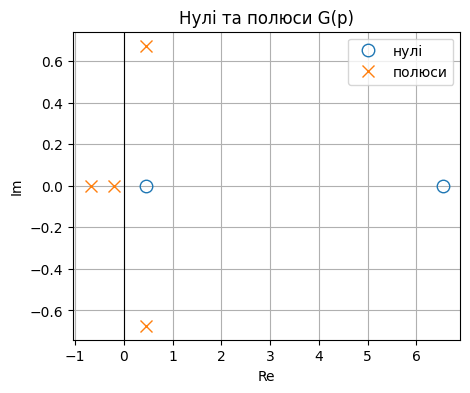

In [2]:
num = [1, -7, 3]            # p^2 - 7p + 3
den = [11, 0, 0, 5, 1]      # 11p^4 + 5p + 1

z, p, gain = signal.tf2zpk(num, den)     # ключова функція: ПФ -> нулі, полюси, коефіцієнт
print("Нулі    :", z)
print("Полюси  :", p)
print("Коеф. k :", gain)
print("Стійка  :", bool(np.all(p.real < 0)))

def fmt(r):                              # допоміжне: (p - корінь)
    return f"(p - ({r.real:.4f}{r.imag:+.4f}j))" if abs(r.imag) > 1e-9 else f"(p - ({r.real:.4f}))"
print(f"\nG(p) = {gain:.4f} · " + "".join(map(fmt, z)) + " / " + "".join(map(fmt, p)))

fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(z.real, z.imag, "o", mfc="none", ms=9, label="нулі")
ax.plot(p.real, p.imag, "x", ms=9, label="полюси")
ax.axvline(0, c="k", lw=.8)
ax.set(xlabel="Re", ylabel="Im", title="Нулі та полюси G(p)"); ax.legend()
plt.show()

**Результат.**

- Нулі: $6{,}5414$ та $0{,}4586$ (обидва в правій півплощині → ланка неминімально-фазова); коефіцієнт $k=1/11\approx0{,}0909$.
- Полюси: $0{,}4446\pm0{,}6732i$, $-0{,}6853$, $-0{,}2038$.
- **Висновок:** пара полюсів має $\mathrm{Re}\,p>0$, тому система **нестійка** (вільний рух зростає як $e^{0{,}44t}$). Те саме видно з коефіцієнтів: у знаменнику немає членів $p^3$ і $p^2$, тобто необхідна умова стійкості (усі коефіцієнти додатні) порушена.

---
## 2. Чи можна стабілізувати систему скалярним $k_u$ (схема Рис. 5)?

**Що робимо.** Замикаємо ланку від'ємним зворотним зв'язком із коефіцієнтом $k_u$ у прямому ланцюгу:

$$W_k(s)=\frac{k_uG}{1+k_uG}=\frac{k_u N(s)}{D(s)+k_uN(s)}.$$

Стійкість визначається коренями характеристичного полінома $D(s)+k_uN(s)$. Знаходимо його символьно (`sympy`) і перебираємо $k_u\in[-200,200]$, відстежуючи найбільшу дійсну частину полюса.

D(s) + k_u·N(s) = k_u*s**2 + 3*k_u + 11*s**4 + s*(5 - 7*k_u) + 1
коефіцієнт при s^3 = 0
найкраще k_u = -0.200, але max Re(полюс) = 0.4415 > 0


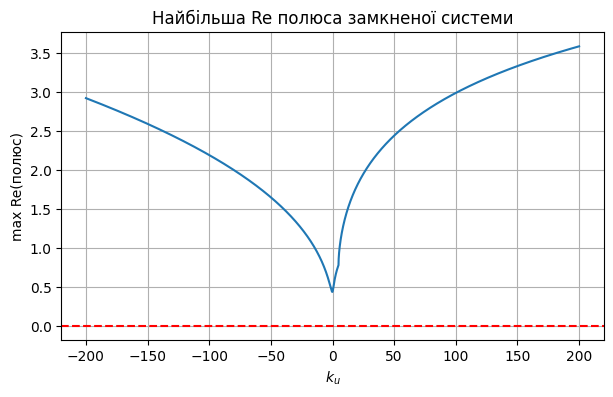

In [3]:
s, kk = sp.symbols("s k_u")
N_s = s**2 - 7*s + 3
D_s = 11*s**4 + 5*s + 1

char = sp.Poly(sp.expand(D_s + kk*N_s), s)               # D(s) + k_u·N(s)
print("D(s) + k_u·N(s) =", char.as_expr())
print("коефіцієнт при s^3 =", char.coeff_monomial(s**3))

ks = np.linspace(-200, 200, 40001)
max_re = np.array([np.roots(np.polyadd(den, kv*np.array(num))).real.max() for kv in ks])
i = max_re.argmin()
print(f"найкраще k_u = {ks[i]:.3f}, але max Re(полюс) = {max_re[i]:.4f} > 0")

plt.plot(ks, max_re); plt.axhline(0, c="r", ls="--")
plt.xlabel("$k_u$"); plt.ylabel("max Re(полюс)"); plt.title("Найбільша Re полюса замкненої системи")
plt.show()

**Результат.**

- $D(s)+k_uN(s)=11s^4+0\cdot s^3+k_us^2+(5-7k_u)s+(1+3k_u)$: коефіцієнт при $s^3$ дорівнює **нулю за будь-якого $k_u$**, тож необхідна умова Гурвіца не виконується. Крім того, сума коренів $=-a_3/a_4=0$, тому хоча б один корінь завжди має $\mathrm{Re}\ge0$.
- Перебір підтверджує: $\max\mathrm{Re}(p)>0$ для всіх $k_u$ (мінімум $\approx0{,}44$ при $k_u\approx-0{,}2$ — майже без покращення відносно розімкненої системи).
- **Висновок:** для варіанту 3 схема Рис. 5 зі скалярним $k_u$ **не дає стійкої системи** (ні для додатного, ні для від'ємного $k_u$). Щоб далі працювати зі стійкою системою, замінюємо $k_u$ вектором $K$ (зворотний зв'язок за станом).

---
## 3. Стабілізація зворотним зв'язком за станом

**Що робимо.** Скалярний $k_u$ замінюємо вектором $K$. Подаємо ланку в канонічній формі керованості (докладно — у завданні 2): $\hat D(p)\,w=u,\; y=\hat N(p)\,w$, де $\hat D,\hat N$ — $D,N$, поділені на 11, а стан $x=(w,w',w'',w''')$. Закон керування (від'ємний зв'язок):

$$u=k_u\,r-Kx,\qquad K=[k_0,k_1,k_2,k_3]\;\Rightarrow\;\hat D_{cl}(p)=\hat D(p)+k_3p^3+k_2p^2+k_1p+k_0,\qquad W(p)=\frac{k_u\hat N(p)}{\hat D_{cl}(p)}.$$

Нулі $W$ збігаються з нулями $G$, а полюси можна призначити довільно. Обираємо бажані полюси $-0{,}4\pm0{,}8i,\;-1,\;-2$ (пара з $\xi\approx0{,}45$ — щоб був помітний резонанс) і знаходимо $K$ порівнянням коефіцієнтів. Множник $k_u$ підбираємо так, щоб $W(0)=1$ (слідкуюча система).

In [4]:
Dh = np.array(den) / 11               # D^(p) = p^4 + (5/11)p + 1/11
Nh = np.array(num) / 11               # N^(p) = (p^2 - 7p + 3)/11

poles_cl = [-0.4 + 0.8j, -0.4 - 0.8j, -1, -2]    # бажані полюси замкненої системи
Dcl = np.poly(poles_cl).real                      # p^4 + 3.8p^3 + 5.2p^2 + 4p + 1.6
K   = (Dcl - Dh)[1:][::-1]                        # [k0, k1, k2, k3] з D_cl = D^ + K(p)
k_u = Dcl[-1] / Nh[-1]                            # щоб W(0) = 1

W = signal.TransferFunction(k_u*Nh, Dcl)          # модель стійкої замкненої ланки
zW, pW, kW = signal.tf2zpk(W.num, W.den)

print("K = [k0, k1, k2, k3] =", K)
print("k_u =", round(k_u, 4))
print("W(p): чисельник", W.num, "| знаменник", W.den)
print(f"W(p) = {kW:.4f} · " + "".join(map(fmt, zW)) + " / " + "".join(map(fmt, pW)))
print("Полюси W:", pW)
print("Стійка  :", bool(np.all(pW.real < 0)))

K = [k0, k1, k2, k3] = [1.5091 3.5455 5.2    3.8   ]
k_u = 5.8667
W(p): чисельник [ 0.5333 -3.7333  1.6   ] | знаменник [1.  3.8 5.2 4.  1.6]
W(p) = 0.5333 · (p - (6.5414))(p - (0.4586)) / (p - (-2.0000))(p - (-1.0000))(p - (-0.4000+0.8000j))(p - (-0.4000-0.8000j))
Полюси W: [-2. +0.j  -1. +0.j  -0.4+0.8j -0.4-0.8j]
Стійка  : True


**Результат.**

- $K=[k_0,k_1,k_2,k_3]=[1{,}5091;\;3{,}5455;\;5{,}2;\;3{,}8]$, $k_u=5{,}8667$.
- Передатна функція замкненої системи:

$$W(p)=\frac{1{,}6}{3}\cdot\frac{p^2-7p+3}{p^4+3{,}8p^3+5{,}2p^2+4p+1{,}6},\qquad W(0)=1.$$

- Полюси: $-0{,}4\pm0{,}8i,\;-1,\;-2$ — усі в лівій півплощині, **система стійка**. Нулі ті самі, що й у $G$ (зворотний зв'язок за станом їх не змінює).

Далі працюємо саме з $W(p)$.

---
## 4. Імпульсна характеристика та перехідна функція

**Що робимо.** Модель ланки — об'єкт `signal.TransferFunction` (`W`). Імпульсну характеристику $h(t)$ (реакцію на $\delta$-імпульс) будуємо `signal.impulse`, перехідну функцію $c(t)$ (реакцію на одиничний стрибок) — `signal.step`. Додатково знаходимо показники якості: усталене значення, перерегулювання, час регулювання (допуск 2 %).

c(∞) = 1.000
max c = 1.199  (перерегулювання 19.9 %) при t = 6.79 c
min c = -0.442  (протифазний прогин при t = 2.19 c)
час регулювання (2 %) = 12.1 c


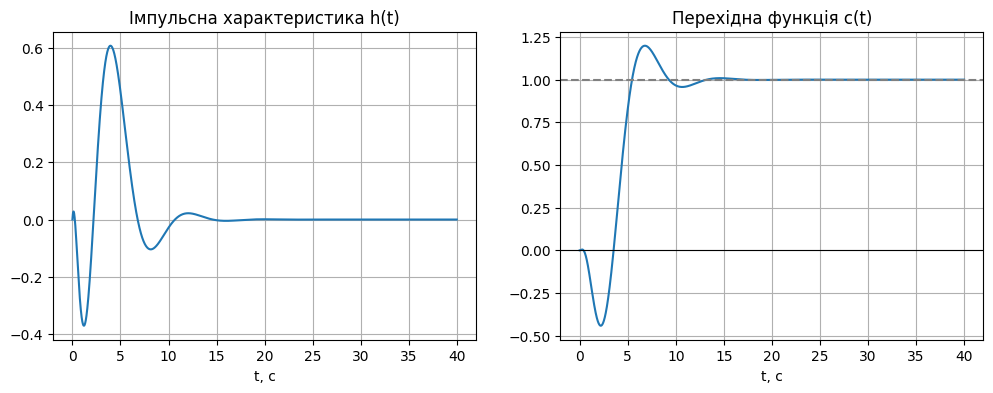

In [5]:
t = np.linspace(0, 40, 4001)
_, h = signal.impulse(W, T=t)          # імпульсна характеристика h(t)
_, c = signal.step(W, T=t)             # перехідна функція c(t)

c_ss = np.polyval(W.num, 0) / np.polyval(W.den, 0)       # усталене значення = W(0)
t_s = t[np.where(np.abs(c - c_ss) > 0.02*c_ss)[0][-1]]    # час регулювання (2 %)
print(f"c(∞) = {c_ss:.3f}")
print(f"max c = {c.max():.3f}  (перерегулювання {(c.max()/c_ss - 1)*100:.1f} %) при t = {t[c.argmax()]:.2f} c")
print(f"min c = {c.min():.3f}  (протифазний прогин при t = {t[c.argmin()]:.2f} c)")
print(f"час регулювання (2 %) = {t_s:.1f} c")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(t, h); ax[0].set(title="Імпульсна характеристика h(t)", xlabel="t, c")
ax[1].plot(t, c); ax[1].axhline(c_ss, c="gray", ls="--"); ax[1].axhline(0, c="k", lw=.8)
ax[1].set(title="Перехідна функція c(t)", xlabel="t, c")
plt.show()

**Результат.**

- Усталене значення $c(\infty)=1$, перерегулювання $\approx19{,}9\,\%$ (максимум $1{,}199$ при $t\approx6{,}8$ с), час регулювання (2 %) $\approx12{,}1$ с. Імпульсна характеристика загасає до нуля — ознака стійкості.
- На початку $c(t)$ йде у **протилежний бік** (мінімум $\approx-0{,}44$ при $t\approx2{,}2$ с), і лише потім зростає до 1. Це наслідок нулів у правій півплощині (неминімально-фазова ланка); імпульсна характеристика теж спочатку змінює знак.

---
## 5. Відгук на гармонічний вхідний сигнал

**Що робимо.** Подаємо $u(t)=\sin\omega_0 t$ на вхід (`signal.lsim`), чекаємо завершення перехідного процесу й по усталеній частині знаходимо амплітуду та фазу виходу: підганяємо $y\approx a\sin\omega_0t+b\cos\omega_0t$ методом найменших квадратів, тоді коефіцієнт посилення $=\sqrt{a^2+b^2}$, зсув фази $=\operatorname{atan2}(b,a)$. Результат порівнюємо з $|W(i\omega_0)|$ та $\arg W(i\omega_0)$ із `signal.freqresp`.

**Вхідні дані:** частоти $\omega_0=0{,}3;\;0{,}76;\;2;\;5$ рад/с.

 ω, рад/с | K (модель) |  |W(iω)| | φ (модель), ° | arg W(iω), °
     0.30 |     1.2095 |   1.2095 |        -79.72 |       -79.72
     0.76 |     1.7920 |   1.7920 |        166.53 |       166.53
     2.00 |     0.3308 |   0.3308 |          4.04 |         4.04
     5.00 |     0.0327 |   0.0327 |        -79.66 |       -79.66


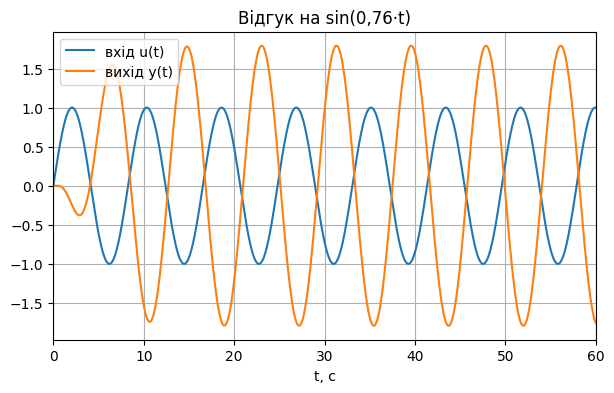

In [6]:
def harmonic_response(sys, w0, T_end=120):
    t = np.linspace(0, T_end, 24001)
    u = np.sin(w0*t)
    _, y, _ = signal.lsim(sys, u, t)                        # відгук на гармоніку
    m = t > T_end/2                                          # усталена частина
    M = np.c_[np.sin(w0*t[m]), np.cos(w0*t[m])]
    a, b = np.linalg.lstsq(M, y[m], rcond=None)[0]           # y = a·sin + b·cos
    return t, u, y, np.hypot(a, b), np.degrees(np.arctan2(b, a))

print(f"{'ω, рад/с':>9} | {'K (модель)':>10} | {'|W(iω)|':>8} | {'φ (модель), °':>13} | {'arg W(iω), °':>12}")
for w0 in [0.3, 0.76, 2.0, 5.0]:
    *_, K_est, phi_est = harmonic_response(W, w0)
    _, Hw = signal.freqresp(W, [w0])
    print(f"{w0:9.2f} | {K_est:10.4f} | {abs(Hw[0]):8.4f} | {phi_est:13.2f} | {np.degrees(np.angle(Hw[0])):12.2f}")

t5, u5, y5, *_ = harmonic_response(W, 0.76)
plt.plot(t5, u5, label="вхід u(t)"); plt.plot(t5, y5, label="вихід y(t)")
plt.xlim(0, 60); plt.xlabel("t, c"); plt.title("Відгук на sin(0,76·t)"); plt.legend(); plt.show()

**Результат.**

- Вихід — гармоніка тієї самої частоти зі зміненими амплітудою та фазою; коефіцієнт посилення й зсув фази з моделі збігаються з $|W(i\omega)|$ та $\arg W(i\omega)$ (до 4 знаків).
- Посилення $\approx1{,}21$ при $\omega=0{,}3$; $\approx1{,}79$ при $\omega=0{,}76$ (найбільше — поблизу резонансу); $0{,}33$ при $\omega=2$; $0{,}03$ при $\omega=5$ (високі частоти гасяться).
- Фаза визначена з точністю до $360^\circ$: наприклад, $166{,}5^\circ\equiv-193{,}5^\circ$ при $\omega=0{,}76$, тобто вихід відстає від входу.

---
## 6. Годограф Найквіста, АЧХ та ФЧХ

**Що робимо.** Частотну характеристику $W(i\omega)$ обчислюємо `signal.freqresp` (звідси годограф Найквіста — крива $\mathrm{Im}\,W$ від $\mathrm{Re}\,W$), а `signal.bode` дає АЧХ у дБ та ФЧХ у градусах. З АЧХ знаходимо резонансну частоту $\omega_r$, пік $M_r$ та смугу пропускання $\omega_B$ (спад на 3 дБ відносно низьких частот).

ω_r = 0.758 рад/с,  M_r = 1.792 (5.07 дБ),  M_r/W(0) = 1.792
смуга пропускання ω_B = 1.461 рад/с
локальні мінімуми АЧХ (провали): []
домінантна пара: ω_n = 0.894, ξ = 0.447; оцінка ω_r ≈ ω_n·√(1-2ξ²) = 0.693


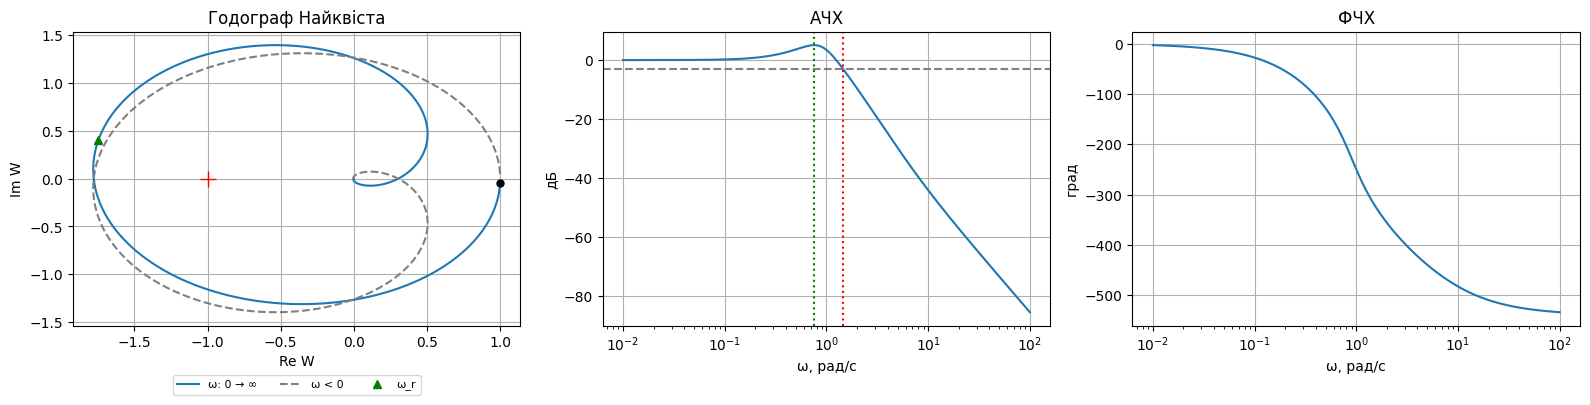

In [7]:
w = np.logspace(-2, 2, 4000)
_, H = signal.freqresp(W, w)                        # H(iω) — для годографа
_, mag_db, phase = signal.bode(W, w)                # АЧХ (дБ) і ФЧХ (°)
mag = np.abs(H)

i_r = mag.argmax();  w_r, M_r = w[i_r], mag[i_r]                 # резонанс
w_B = w[np.where(mag < mag[0]/np.sqrt(2))[0][0]]                  # смуга пропускання (-3 дБ)
minima = w[1:-1][(mag[1:-1] < mag[:-2]) & (mag[1:-1] < mag[2:])]  # локальні мінімуми АЧХ ("запирання")

print(f"ω_r = {w_r:.3f} рад/с,  M_r = {M_r:.3f} ({20*np.log10(M_r):.2f} дБ),  M_r/W(0) = {M_r/mag[0]:.3f}")
print(f"смуга пропускання ω_B = {w_B:.3f} рад/с")
print("локальні мінімуми АЧХ (провали):", minima)

# оцінка за домінантною парою полюсів
pd = pW[np.argmax(pW.imag)]
wn, xi = abs(pd), -pd.real/abs(pd)
print(f"домінантна пара: ω_n = {wn:.3f}, ξ = {xi:.3f}; оцінка ω_r ≈ ω_n·√(1-2ξ²) = {wn*np.sqrt(1-2*xi**2):.3f}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].plot(H.real, H.imag, label="ω: 0 → ∞"); ax[0].plot(H.real, -H.imag, "--", c="gray", label="ω < 0")
ax[0].plot(-1, 0, "r+", ms=12); ax[0].plot(H.real[0], H.imag[0], "ko", ms=5)
ax[0].plot(H.real[i_r], H.imag[i_r], "g^", label="ω_r")
ax[0].set(title="Годограф Найквіста", xlabel="Re W", ylabel="Im W")
ax[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=8)
ax[1].semilogx(w, mag_db); ax[1].axvline(w_r, c="g", ls=":"); ax[1].axvline(w_B, c="r", ls=":")
ax[1].axhline(20*np.log10(mag[0]) - 3, c="gray", ls="--")
ax[1].set(title="АЧХ", xlabel="ω, рад/с", ylabel="дБ")
ax[2].semilogx(w, phase); ax[2].set(title="ФЧХ", xlabel="ω, рад/с", ylabel="град")
plt.tight_layout(); plt.show()

**Результат і коментарі.**

- **Резонанс є:** $M_r\approx1{,}79$ (5,07 дБ) на $\omega_r\approx0{,}76$ рад/с; це близько до власної частоти домінантної пари полюсів $\omega_n=0{,}894$ при слабкому загасанні $\xi=0{,}447<0{,}707$. Смуга пропускання $\omega_B\approx1{,}46$ рад/с.
- **Явища замкнення («запирання») немає:** АЧХ не має провалів (локальних мінімумів), бо нулі дійсні й не лежать на уявній осі; після піку АЧХ монотонно спадає ($-40$ дБ/дек).
- **Резонанс і стійкість:** резонансний пік тим вищий, чим ближче полюси до уявної осі (менше $\xi$); на межі стійкості ($\xi\to0$) $M_r\to\infty$. Наша система стійка, але запас невеликий — звідси пік і перерегулювання. Оцінка за формулою для коливної ланки ($\omega_r\approx0{,}69$) відрізняється від точного значення, бо на АЧХ впливають ще й нулі та дійсні полюси.
- **Годограф:** починається в точці $W(0)=1$, обходить початок координат за годинниковою стрілкою (фаза йде аж до $-540^\circ$), найбільш віддалений від початку координат поблизу $\omega_r$ ($|W|=1{,}79$), потім закручується в малу петлю й закінчується в нулі.

**Зв'язок між АЧХ і ФЧХ.** Для мінімально-фазових ланок (усі нулі й полюси в лівій півплощині) ФЧХ однозначно випливає з АЧХ (співвідношення Бодє). Перевіряємо це для $W$: «віддзеркалюємо» нулі з правої півплощини в ліву — АЧХ не змінюється ($|i\omega-z|=|i\omega+z|$ для дійсного $z$), а ФЧХ змінюється.

max | |W| - |W_mp| | = 2.4424906541753444e-15


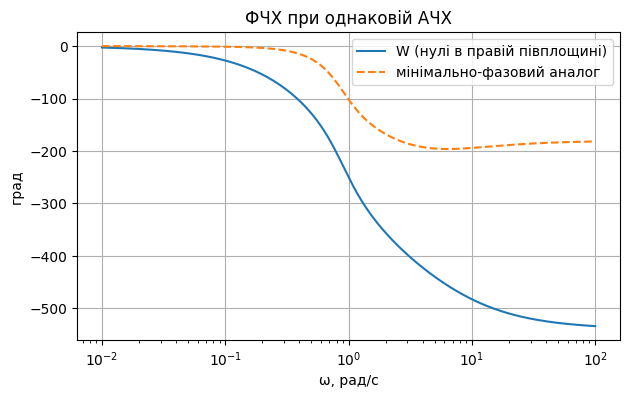

In [8]:
z_mp = -np.abs(zW)                                          # нулі, віддзеркалені в ліву півплощину
W_mp = signal.ZerosPolesGain(z_mp, pW, kW)                  # мінімально-фазовий аналог
_, H_mp = signal.freqresp(W_mp, w)

print("max | |W| - |W_mp| | =", np.max(np.abs(np.abs(H) - np.abs(H_mp))))
plt.semilogx(w, phase, label="W (нулі в правій півплощині)")
plt.semilogx(w, np.unwrap(np.angle(H_mp))*180/np.pi, "--", label="мінімально-фазовий аналог")
plt.xlabel("ω, рад/с"); plt.ylabel("град"); plt.title("ФЧХ при однаковій АЧХ"); plt.legend(); plt.show()

**Результат.** АЧХ обох ланок збігається ($\Delta\approx10^{-15}$), а ФЧХ різні: у мінімально-фазового аналога фаза обмежена ($\to-180^\circ$), а у $W$ додатково «набігає» відставання аж до $-540^\circ$ — його дає всепропускна складова з нулями в правій півплощині.

**Висновок:** між АЧХ і ФЧХ **є зв'язок**: для мінімально-фазових ланок ФЧХ однозначно визначається АЧХ (співвідношення Бодє, перетворення Гільберта). Для неминімально-фазових ланок за АЧХ фазу однозначно відновити не можна — додається фаза всепропускної ланки.

---
## 7. Диференціальне рівняння, що відповідає $W(p)$

**Що робимо.** За коефіцієнтами $W(p)$ (помноживши чисельник і знаменник на 15, щоб коефіцієнти стали цілими) формуємо рівняння

$$a_ny^{(n)}+\dots+a_0y=b_mu^{(m)}+\dots+b_0u,$$

записуємо його в `sympy`, зводимо до системи першого порядку відносно $z=(y,y',y'',y''')$ і розв'язуємо `solve_ivp`. Щоб початкові умови були нульовими (як у передатній функції), беремо гладкі входи, у яких $u(0)=u'(0)=u''(0)=0$: $u_1=t^3e^{-t}$ та $u_2=\sin^3 t$. Порівнюємо розв'язок з відгуком моделі `lsim`.

In [9]:
tt = sp.symbols("t")
y, u = sp.Function("y"), sp.Function("u")

numI = np.round(15*W.num).astype(int)     # [8, -56, 24]
denI = np.round(15*W.den).astype(int)     # [15, 57, 78, 60, 24]

def ode_from_tf(num_c, den_c):
    n, m = len(den_c) - 1, len(num_c) - 1
    lhs = sum(int(c) * y(tt).diff(tt, n - i) for i, c in enumerate(den_c))
    rhs = sum(int(c) * u(tt).diff(tt, m - i) for i, c in enumerate(num_c))
    return sp.Eq(lhs, rhs)

print("Вихідна G(p):"); sp.pprint(ode_from_tf(num, den))
print("\nЗамкнена W(p):"); sp.pprint(ode_from_tf(numI, denI))

Вихідна G(p):
                        4                                 2       
         d             d                      d          d        
y(t) + 5⋅──(y(t)) + 11⋅───(y(t)) = 3⋅u(t) - 7⋅──(u(t)) + ───(u(t))
         dt              4                    dt           2      
                       dt                                dt       

Замкнена W(p):
                            2              3              4                    ↪
             d             d              d              d                     ↪
24⋅y(t) + 60⋅──(y(t)) + 78⋅───(y(t)) + 57⋅───(y(t)) + 15⋅───(y(t)) = 24⋅u(t) - ↪
             dt              2              3              4                   ↪
                           dt             dt             dt                    ↪

↪                   2       
↪     d            d        
↪  56⋅──(u(t)) + 8⋅───(u(t))
↪     dt             2      
↪                  dt       


u = t³·e^(−t) : max|y_ДР - y_ПФ| = 5.19e-06
u = sin³ t    : max|y_ДР - y_ПФ| = 1.16e-05


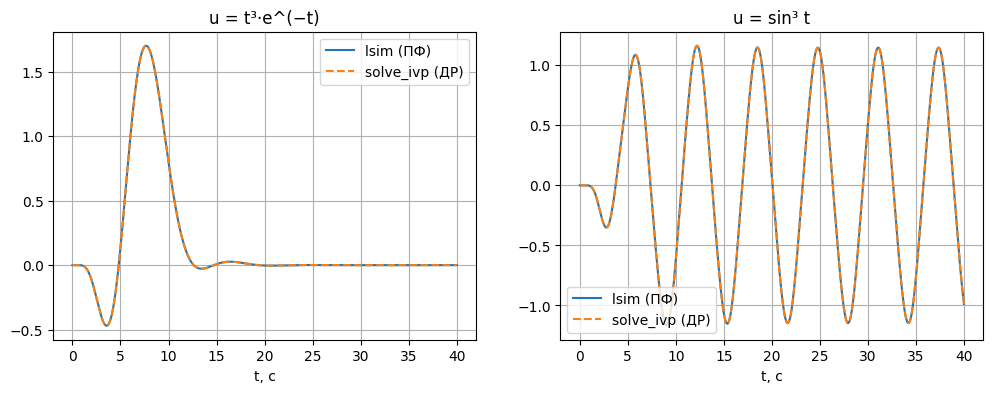

In [10]:
n, m = len(denI) - 1, len(numI) - 1

def solve_ode(u_expr, t_eval):
    du = [sp.lambdify(tt, sp.diff(u_expr, tt, k), "numpy") for k in range(m + 1)]   # u, u', u''
    def rhs(t_, zv):                                  # zv = [y, y', y'', y''']
        right = sum(numI[m - k]*du[k](t_) for k in range(m + 1))                    # Σ b_k u^(k)
        left  = sum(denI[n - k]*zv[k] for k in range(n))                            # Σ a_k y^(k), k < n
        return [*zv[1:], (right - left)/denI[0]]
    return solve_ivp(rhs, (t_eval[0], t_eval[-1]), np.zeros(n), t_eval=t_eval, rtol=1e-10, atol=1e-12).y[0]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a_, (name, ue) in zip(ax, {"t³·e^(−t)": tt**3*sp.exp(-tt), "sin³ t": sp.sin(tt)**3}.items()):
    uv = sp.lambdify(tt, ue, "numpy")(t)
    y_ode = solve_ode(ue, t)                           # розв'язок диференціального рівняння
    _, y_tf, _ = signal.lsim(W, uv, t)                 # відгук моделі W(p)
    print(f"u = {name:10s}: max|y_ДР - y_ПФ| = {np.max(np.abs(y_ode - y_tf)):.2e}")
    a_.plot(t, y_tf, label="lsim (ПФ)"); a_.plot(t, y_ode, "--", label="solve_ivp (ДР)")
    a_.set(title=f"u = {name}", xlabel="t, c"); a_.legend()
plt.show()

**Результат.**

- Диференціальні рівняння:
  - вихідна ланка: $11y^{(4)}+5y'+y=u''-7u'+3u$ (нестійка);
  - замкнена система: $15y^{(4)}+57y^{(3)}+78y''+60y'+24y=8u''-56u'+24u$.
- Розв'язок ДР для обох вхідних сигналів збігається з відгуком моделі `lsim` (максимальна різниця $\sim10^{-5}$ — похибка інтерполяції входу в `lsim`). Отже, диференціальне рівняння й передатна функція задають **те саме відображення «вхід–вихід»**.

---
## 8. Висновки та контрольні питання

**Висновки**

1. $G(p)$ має полюси $0{,}44\pm0{,}67i$ у правій півплощині → система нестійка; нулі $6{,}54$ та $0{,}46$ теж у правій півплощині (неминімально-фазова).
2. Скалярний $k_u$ за схемою Рис. 5 не стабілізує варіант 3 (нульовий коефіцієнт при $s^3$ у характеристичному поліномі за будь-якого $k_u$). Стабілізовано зворотним зв'язком за станом: $K=[1{,}5091;\,3{,}5455;\,5{,}2;\,3{,}8]$, $k_u=5{,}8667$.
3. Стійка система: $c(\infty)=1$, перерегулювання $19{,}9\,\%$, $t_{рег}\approx12{,}1$ с, резонанс $M_r=1{,}79$ на $\omega_r=0{,}76$ рад/с, $\omega_B=1{,}46$ рад/с, «запирання» немає.
4. Відгук на гармоніку: коефіцієнт посилення та зсув фази з моделі збігаються з $|W(i\omega)|$ і $\arg W(i\omega)$.
5. ДР і передатна функція дають однакове відображення «вхід–вихід».

**Контрольні питання**

*2.3.1. Навіщо різноманіття моделей лінійної поведінки?* Різні моделі зручні для різних задач: диференціальне рівняння й імпульсна характеристика (часова область) — для опису процесів і моделювання; передатна функція (операторна) — для алгебраїчного аналізу, з'єднання ланок і стійкості; $W(i\omega)$ (частотна) — для аналізу резонансів і смуги пропускання; опис у просторі станів — для багатовимірних систем і синтезу. Усі вони еквівалентні за відображенням «вхід–вихід», але виявляють різні властивості системи.

*2.3.2. Критерій фізичної реалізованості ПФ.* Дійсні коефіцієнти й степінь чисельника не вище степеня знаменника ($m\le n$, ПФ правильна); для ланки без випередження — $m<n$. Тоді реакція причинна: вихід у момент $t$ не залежить від майбутніх значень входу.